In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

from brian2 import *


INFO       Cache size for target 'cython': 2369 MB.
You can call clear_cache('cython') to delete all files from the cache or manually delete files in the '/home/vincent/.cython/brian_extensions' directory. [brian2]


In [5]:

start_scope()

SEED = 2
seed(SEED)
rng = np.random.default_rng(SEED)

# ----------------------------
# Simulation
# ----------------------------
DT = 0.025*ms
REC_DT = 0.5*ms
SIM_TIME = 3*second

defaultclock.dt = DT

# ----------------------------
# Population sizes
# ----------------------------
NE = 400
NI = 100

# ----------------------------
# Hodgkin-Huxley membrane
# Classical HH conductance densities scaled to ~20,000 um^2 membrane
# ----------------------------
CM = 200*pF

G_NA = 24*uS
G_K  = 7.2*uS
G_L  = 60*nS

E_NA = 50*mV
E_K  = -77*mV
E_L  = -54.4*mV

# ----------------------------
# Synapses
# ----------------------------
E_AMPA = 0*mV
E_GABA = -80*mV

TAU_AMPA = 5*ms

# Slower GABA_A decay than a gamma-biased network.
# This is one of the main knobs for moving the population rhythm
# toward beta.
TAU_GABA = 18*ms

# Conductance jumps
W_EE = 0.8*nS
W_EI = 1.5*nS
W_IE = 5.0*nS
W_II = 3.0*nS

# Sparse random connection probabilities
P_EE = 0.08
P_EI = 0.10
P_IE = 0.10
P_II = 0.10

# Random synaptic delays
DELAY_E_MIN = 1.0*ms
DELAY_E_MAX = 3.0*ms

DELAY_I_MIN = 2.0*ms
DELAY_I_MAX = 5.0*ms

# ----------------------------
# External/background drive
# ----------------------------
# These values are deliberately chosen to avoid the silent regime.
# If the network fires too much, first reduce RATE_EXT_E or W_EXT_E.
# If it is silent, first increase them.
I_TONIC_E = 0.40*nA
I_TONIC_I = 0.30*nA

N_EXT_E = 300
N_EXT_I = 250

RATE_EXT_E = 8*Hz
RATE_EXT_I = 8*Hz

W_EXT_E = 1.3*nS
W_EXT_I = 1.1*nS

# ----------------------------
# HH equations
# ----------------------------
eqs = r'''
dv/dt = (
      G_NA*m**3*h*(E_NA-v)
    + G_K*n**4*(E_K-v)
    + G_L*(E_L-v)
    + gA*(E_AMPA-v)
    + gG*(E_GABA-v)
    + I_tonic
    )/CM : volt

dm/dt = alpha_m*(1-m) - beta_m*m : 1
dh/dt = alpha_h*(1-h) - beta_h*h : 1
dn/dt = alpha_n*(1-n) - beta_n*n : 1

alpha_m = 1.0/exprel(-(v + 40*mV)/(10*mV))/ms : Hz
beta_m  = 4.0*exp(-(v + 65*mV)/(18*mV))/ms : Hz

alpha_h = 0.07*exp(-(v + 65*mV)/(20*mV))/ms : Hz
beta_h  = 1.0/(1.0 + exp(-(v + 35*mV)/(10*mV)))/ms : Hz

alpha_n = 0.1/exprel(-(v + 55*mV)/(10*mV))/ms : Hz
beta_n  = 0.125*exp(-(v + 65*mV)/(80*mV))/ms : Hz

dgA/dt = -gA/TAU_AMPA : siemens
dgG/dt = -gG/TAU_GABA : siemens

I_tonic : amp
'''

namespace = {
    'CM': CM,
    'G_NA': G_NA,
    'G_K': G_K,
    'G_L': G_L,
    'E_NA': E_NA,
    'E_K': E_K,
    'E_L': E_L,
    'E_AMPA': E_AMPA,
    'E_GABA': E_GABA,
    'TAU_AMPA': TAU_AMPA,
    'TAU_GABA': TAU_GABA,
}

# ----------------------------
# Neurons
# ----------------------------
E = NeuronGroup(
    NE,
    eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='E'
)

I = NeuronGroup(
    NI,
    eqs,
    threshold='v > 0*mV',
    refractory=2*ms,
    method='rk4',
    namespace=namespace,
    name='I'
)

# HH resting initial conditions
for G in (E, I):
    G.v = -65*mV
    G.m = 0.0529
    G.h = 0.596
    G.n = 0.318
    G.gA = 0*nS
    G.gG = 0*nS

# Mild cell-to-cell tonic heterogeneity
E.I_tonic = np.clip(
    rng.normal(float(I_TONIC_E/nA), 0.05, NE),
    0.05, None
)*nA

I.I_tonic = np.clip(
    rng.normal(float(I_TONIC_I/nA), 0.04, NI),
    0.05, None
)*nA

# ----------------------------
# Sparse random recurrent connectivity
# ----------------------------

# E -> E, AMPA
S_EE = Synapses(
    E, E,
    on_pre='gA_post += W_EE',
    namespace={'W_EE': W_EE},
    name='S_EE'
)
S_EE.connect(condition='i != j', p=P_EE)
S_EE.delay = '1*ms + rand()*2*ms'

# E -> I, AMPA
S_EI = Synapses(
    E, I,
    on_pre='gA_post += W_EI',
    namespace={'W_EI': W_EI},
    name='S_EI'
)
S_EI.connect(p=P_EI)
S_EI.delay = '1*ms + rand()*2*ms'

# I -> E, GABA_A
S_IE = Synapses(
    I, E,
    on_pre='gG_post += W_IE',
    namespace={'W_IE': W_IE},
    name='S_IE'
)
S_IE.connect(p=P_IE)
S_IE.delay = '2*ms + rand()*3*ms'

# I -> I, GABA_A
S_II = Synapses(
    I, I,
    on_pre='gG_post += W_II',
    namespace={'W_II': W_II},
    name='S_II'
)
S_II.connect(condition='i != j', p=P_II)
S_II.delay = '2*ms + rand()*3*ms'

# ----------------------------
# Independent Poisson background
# ----------------------------
P_EXT_E = PoissonInput(
    E, 'gA',
    N=N_EXT_E,
    rate=RATE_EXT_E,
    weight=W_EXT_E
)

P_EXT_I = PoissonInput(
    I, 'gA',
    N=N_EXT_I,
    rate=RATE_EXT_I,
    weight=W_EXT_I
)

# ----------------------------
# Monitors
# ----------------------------
# All E voltages and synaptic conductances are recorded so that after
# the run you can inspect any chosen neuron by index.
M_E = StateMonitor(
    E,
    ['v', 'gA', 'gG'],
    record=True,
    dt=REC_DT,
    name='M_E'
)

M_I = StateMonitor(
    I,
    ['v'],
    record=True,
    dt=REC_DT,
    name='M_I'
)

SP_E = SpikeMonitor(E, name='SP_E')
SP_I = SpikeMonitor(I, name='SP_I')

RATE_E = PopulationRateMonitor(E, name='RATE_E')
RATE_I = PopulationRateMonitor(I, name='RATE_I')

net = Network(
    E, I,
    S_EE, S_EI, S_IE, S_II,
    P_EXT_E, P_EXT_I,
    M_E, M_I,
    SP_E, SP_I,
    RATE_E, RATE_I
)

# ============================================================
# LFP PROXIES / PLOTTING HELPERS
# ============================================================

def population_lfp_proxy():
    '''
    Crude population LFP proxy for a non-spatial point-neuron network.

    Since this model has no neuron positions and no dendritic geometry,
    there is no "local electrode" or "middle of the grid".

    The proxy is the population-average magnitude of excitatory and
    inhibitory synaptic currents onto E neurons:

        LFP ~ mean_i( |I_AMPA,i| + |I_GABA,i| )

    This is useful for finding collective oscillations, but it is not a
    biophysical extracellular forward model.
    '''
    I_AMPA = np.asarray(
        (M_E.gA * (E_AMPA - M_E.v))/nA
    )

    I_GABA = np.asarray(
        (M_E.gG * (E_GABA - M_E.v))/nA
    )

    lfp = np.mean(
        np.abs(I_AMPA) + np.abs(I_GABA),
        axis=0
    )

    return np.asarray(M_E.t/second), lfp


def single_neuron_input_proxy(chosen_idx):
    '''
    Synaptic input current magnitude onto one chosen E neuron.
    This is NOT an LFP; it is useful only to compare one cell's input
    to the population signal.
    '''
    I_AMPA = np.asarray(
        (M_E.gA[chosen_idx] * (E_AMPA - M_E.v[chosen_idx]))/nA
    )

    I_GABA = np.asarray(
        (M_E.gG[chosen_idx] * (E_GABA - M_E.v[chosen_idx]))/nA
    )

    return np.abs(I_AMPA) + np.abs(I_GABA)


def print_basic_rates():
    sim_s = float(SIM_TIME/second)

    mean_rate_E = len(SP_E.i)/(NE*sim_s)
    mean_rate_I = len(SP_I.i)/(NI*sim_s)

    print(f'E spikes: {len(SP_E.i)}')
    print(f'I spikes: {len(SP_I.i)}')
    print(f'Mean E rate: {mean_rate_E:.2f} Hz/neuron')
    print(f'Mean I rate: {mean_rate_I:.2f} Hz/neuron')


def plot_network_summary(chosen_idx=NE//2, discard_s=0.5, fmax=120):
    t = np.asarray(M_E.t/second)
    lfp_t, lfp = population_lfp_proxy()
    single_input = single_neuron_input_proxy(chosen_idx)

    # ------------------------
    # One chosen E neuron
    # ------------------------
    show_from = max(discard_s, t[-1] - 1.0)
    zoom = t >= show_from

    fig, ax = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

    ax[0].plot(
        t[zoom],
        np.asarray(M_E.v[chosen_idx]/mV)[zoom],
        lw=0.7
    )
    ax[0].set_ylabel('V_E (mV)')
    ax[0].set_title(f'Chosen E neuron {chosen_idx}')

    ax[1].plot(t[zoom], single_input[zoom], lw=0.8)
    ax[1].set_ylabel('Single-cell\nsynaptic input')

    ax[2].plot(lfp_t[zoom], lfp[zoom], lw=0.8)
    ax[2].set_ylabel('Population\nLFP proxy')
    ax[2].set_xlabel('Time (s)')

    plt.tight_layout()
    plt.show()

    # ------------------------
    # Raster
    # ------------------------
    plt.figure(figsize=(12, 4))
    plt.plot(
        np.asarray(SP_E.t/second),
        np.asarray(SP_E.i),
        '.',
        markersize=2,
        label='E'
    )
    plt.xlabel('Time (s)')
    plt.ylabel('E neuron index')
    plt.title('Excitatory spike raster')
    plt.tight_layout()
    plt.show()

    # ------------------------
    # Population rates
    # ------------------------
    plt.figure(figsize=(12, 4))

    rate_E = RATE_E.smooth_rate(window='gaussian', width=5*ms)/Hz
    rate_I = RATE_I.smooth_rate(window='gaussian', width=5*ms)/Hz

    plt.plot(RATE_E.t/second, rate_E, label='E population rate')
    plt.plot(RATE_I.t/second, rate_I, label='I population rate')

    plt.xlabel('Time (s)')
    plt.ylabel('Population rate (Hz)')
    plt.title('Smoothed population firing rate')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # ------------------------
    # LFP PSD
    # ------------------------
    keep_t = lfp_t >= discard_s
    x = signal.detrend(lfp[keep_t])

    fs = 1.0 / float(REC_DT/second)
    nperseg = min(len(x), int(1.5*fs))

    f, pxx = signal.welch(
        x,
        fs=fs,
        nperseg=nperseg,
        detrend='constant'
    )

    band = (f >= 5) & (f <= fmax)
    beta = (f >= 13) & (f <= 30)

    if np.any(beta):
        beta_peak = f[beta][np.argmax(pxx[beta])]
        print(f'Largest PSD frequency in beta band: {beta_peak:.2f} Hz')

    plt.figure(figsize=(10, 4))
    plt.semilogy(f[band], pxx[band])
    plt.axvspan(13, 30, alpha=0.15, label='beta 13-30 Hz')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('PSD')
    plt.title('Population LFP proxy — PSD')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # ------------------------
    # Spectrogram
    # ------------------------
    nper = int(0.75*fs)
    nover = int(0.65*fs)

    f_s, tt, Sxx = signal.spectrogram(
        signal.detrend(lfp),
        fs=fs,
        nperseg=nper,
        noverlap=nover,
        scaling='density',
        mode='psd'
    )

    freq_mask = (f_s >= 5) & (f_s <= fmax)

    plt.figure(figsize=(12, 5))
    plt.pcolormesh(
        tt,
        f_s[freq_mask],
        10*np.log10(Sxx[freq_mask] + 1e-18),
        shading='auto'
    )
    plt.axhspan(13, 30, alpha=0.10)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.title('Population LFP proxy — spectrogram')
    plt.colorbar(label='Power (dB, arbitrary)')
    plt.tight_layout()
    plt.show()

    return lfp


In [6]:
# ============================================================
# RUN THE MODEL
# ============================================================

net.run(SIM_TIME, report='text')

print_basic_rates()


Starting simulation at t=0. s for a duration of 3. s
1.622175 s (54%) simulated in 10s, estimated 8s remaining.
3. s (100%) simulated in 19s
E spikes: 16626
I spikes: 2643
Mean E rate: 13.86 Hz/neuron
Mean I rate: 8.81 Hz/neuron


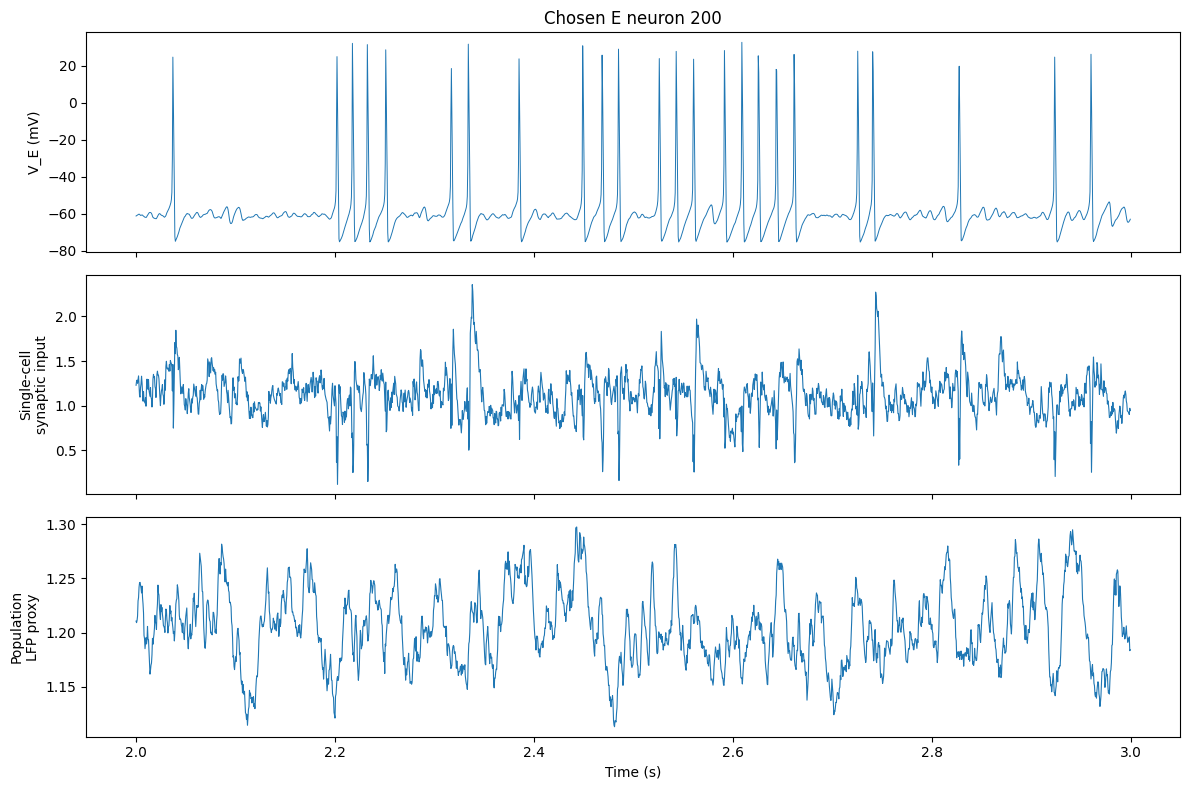

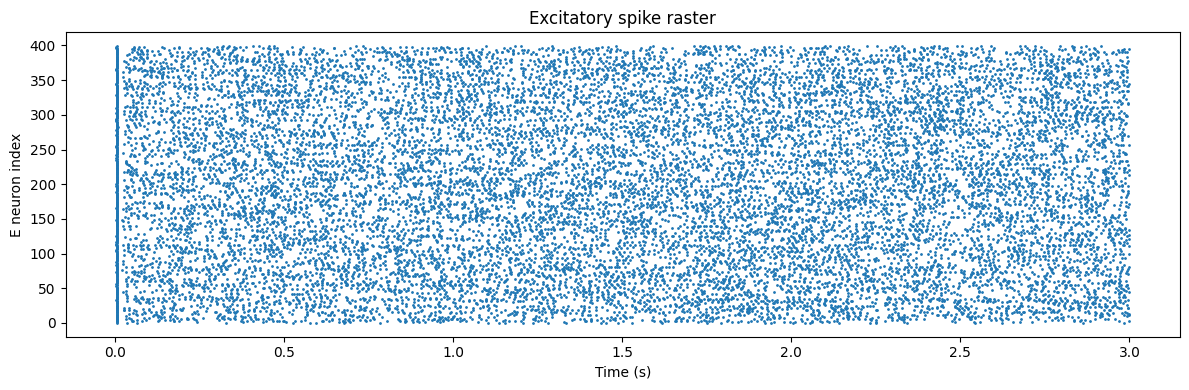

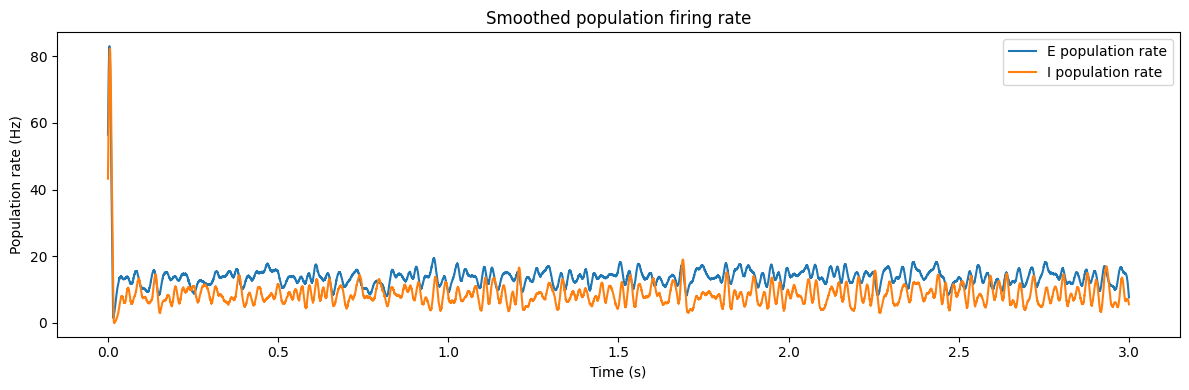

Largest PSD frequency in beta band: 14.67 Hz


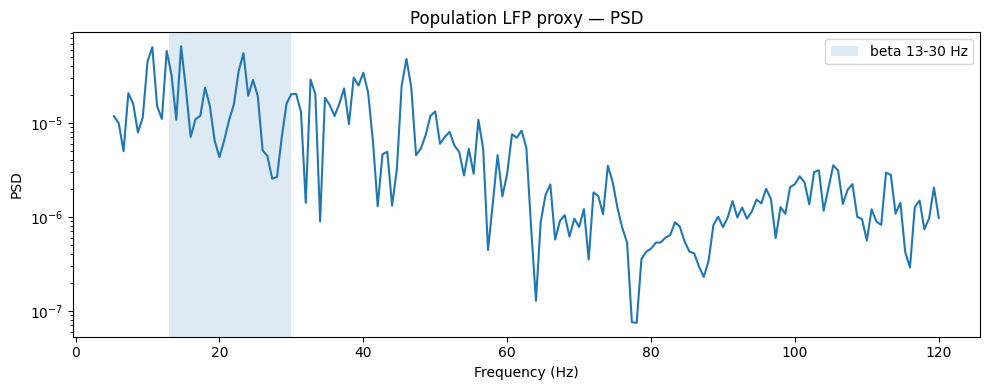

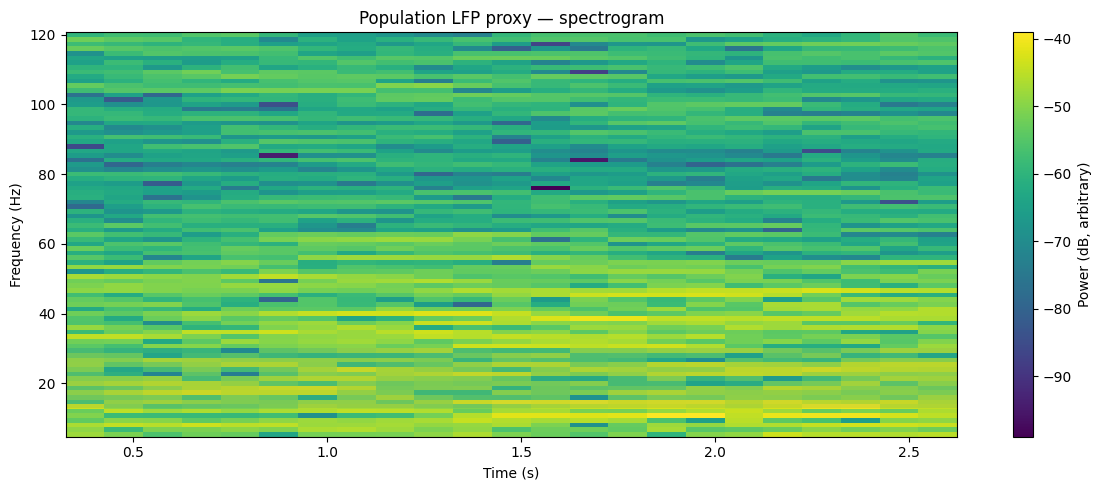

In [7]:


chosen_idx = 200

lfp = plot_network_summary(
    chosen_idx=chosen_idx,
    discard_s=0.5,
    fmax=120
)
